# Analisi modale e statistica della sala secondo la teoria di Schroeder
Il parsing dei dati `.mdat` esportati da REW avviene tramite il modulo `rew_io`.

## Costanti della stanza:

In [1]:
LX, LY, LZ = 5.70, 4.80, 2.48           # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
LT = 4 * (LX + LY + LZ)                  # somma spigoli, 51.9 m
c  = 343.0                               # m/s (~20 degC)

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

from rew_io import ROOM_DIR, FIG_DIR, RESULTS_DIR

RESULTS_DIR.mkdir(exist_ok=True)

print(f'Dimensioni: {LX:.2f} x {LY:.2f} x {LZ:.2f} m')
print(f'Volume = {V:.2f} m^3')
print(f'Superficie = {S:.1f} m^2')
print(f'Dati salvati in: {ROOM_DIR}')

Dimensioni: 5.70 x 4.80 x 2.48 m
Volume = 67.85 m^3
Superficie = 106.8 m^2
Dati salvati in: /Users/matteob/Code/acoustics/data/room


## Parser
Estrazione dei file `.mdat`, contenente dati impacchettati da REW in formato Java. Il **parser** `rew_io` estrapola i dati di interesse dai pacchetti, per tutte le Impulse Response.
`read_mdat` riceve il percorso in cui sono salvati i dati, e restituisce un oggetto `Measurment` composto di:
- `path`: il percorso di salvataggio dati, già in input;
- `field`: tramite `parse_measdata_fields` restituisce un dizionario coi metadati della misura;
- `irs`: tramite `extract_irs` restituisce gli effettivi array di misura degli sweep effettuati su REW, con un controllo sulla lunghezza degli array stessi;

*NOTA: si può tranquillamente togliere la proprietà `room_dims` di `Measurement`, in quanto i dati dimensionali della stanza intrinseci nelle misure *.mdat* sono errati.*

In [2]:
from rew_io import read_mdat

m = read_mdat(ROOM_DIR / 'Danger_Pos1.mdat')
print(f"- Numero di sweep nel file:", len(m.irs))
print(f"- Sweep eseguito tra {m.fields['startFreq']:.1f} Hz e {m.fields['endFreq']:.1f} Hz, con risoluzione di {m.fields['freqStep']:.3f} Hz.")
print(f"- Dati acquisiti con {len(m.irs[0]):.0f} campioni, a {m.fields['sampleRate']:.0f} Hz.")

- Numero di sweep nel file: 3
- Sweep eseguito tra 20.1 Hz e 22000.1 Hz, con risoluzione di 0.366 Hz.
- Dati acquisiti con 131072 campioni, a 48000 Hz.


## Estrazione dati per le 5 posizioni
Analisi preliminare dei dati acquisiti:
- Calcolo della correlazione tra i 3 sweep come controllo sulla riproducibilità.
- SNR per ogni posizione, per attendibilità della IR.

In [3]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

correlations = []
correlazioni_medie = []

print("Correlazione tra ESS in una stessa posizione.")

for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    irs, mean_ir = m.irs, m.mean_ir

    # Correlazione tra gli sweep acquisiti in ciascuna posizione
    temp = []
    for i in range(len(irs)):
        for j in range(i + 1, len(irs)):
            temp.append(np.corrcoef(irs[i], irs[j])[0, 1])

    # Registro il minimo in quanto peggior caso di correlazione
    correlations.append(np.min(temp))
    correlazioni_medie.append(np.mean(temp))

    print(f"Posizione {pos}: {np.min(temp):.6f}")


Correlazione tra ESS in una stessa posizione.
Posizione 1: 0.998758
Posizione 2: 0.990943
Posizione 3: 0.992562
Posizione 4: 0.990373
Posizione 5: 0.988197


## Media delle IRs
Essendo gli sweep per ogni posizione consistenti, spostiamo l'analisi sulle IR mediate, ottenendo verosimilmente un risultato più vicino al valore vero.

*NOTA: eventualmente includere il discorso dell'allineamento*

In [4]:
import numpy as np
from rew_io import read_mdat

POSITIONS = [1, 2, 3, 4, 5]

snr_db = []
for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    mean_ir, fs = m.mean_ir, m.fs

    # SNR
    noise = mean_ir[:40000] # campioni prima dell'inizio dello sweep
    signal = np.abs(mean_ir).max() # considero il massimo del segnale
    snr = 20*np.log10(signal / np.std(noise))
    snr_db.append(snr)
    print(f"Posizione {pos}: SNR = {snr:.2f} dB")

np.savetxt(RESULTS_DIR / 'qualita_misure.csv', np.column_stack([POSITIONS, correlazioni_medie, snr_db]),
           delimiter=',', fmt=['%d', '%.6f', '%.2f'], header='posizione,correlazione_media,snr_db', comments='')

Posizione 1: SNR = 82.14 dB
Posizione 2: SNR = 78.66 dB
Posizione 3: SNR = 79.17 dB
Posizione 4: SNR = 80.12 dB
Posizione 5: SNR = 68.16 dB


## Verifica allineamento IRs
È necessario verificare che le misure, o meglio le risposte impulsive estratte dagli sweep su REW, siano allineate, in modo da avere più avanti un'unica finestra di integrazione per l'integrale di Schroeder.

In [5]:
data = []
for pos in POSITIONS:
    data.append(read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat'))

pass

## Integrale di Schröder
Il modulo `integration` incapsula i passaggi in una dataclass `BandDecay`:

1. `BandDecay.from_ir(ir, fc, fs)` — filtra la IR nella banda d'ottava (fase nulla, `sosfiltfilt`) e taglia al picco, cioè al suono diretto: è l'estremo **iniziale** di integrazione.
2. `.find_limits()` — costruzione di **Lundeby** per l'estremo **finale**: il punto in cui il decadimento incontra il rumore di fondo. Senza il troncamento la coda di rumore, essendo stazionaria, contribuisce sempre di più andando indietro nel tempo: la curva si appiattisce su un plateau e il tempo di riverberazione risulta sovrastimato.
3. `.schroeder()` — integrale all'indietro sull'energia troncata, normalizzato a 0 dB.

La curva integrata di un decadimento esponenziale è una retta in dB: tutto il contenuto fisico sta nella sua pendenza, il resto è estrapolazione. Il fit va da −5 a −25 dB (ISO 3382-1) — i primi 5 dB sono il ginocchio di suono diretto e prime riflessioni, che non appartengono al campo riverberante diffuso — e si estende a −60 dB, cioè $T_{20} = -60/\text{pendenza}$. La norma chiede inoltre che la curva scenda almeno 10 dB sotto l'estremo inferiore del fit; è una condizione da verificare a vista sui grafici della cella seguente.

Il ciclo qui sotto ripete i tre passaggi per ogni posizione microfonica e per ogni banda in `BANDS`, e scrive i $T_{20}$ nel CSV in `data/results/`, da cui partono le analisi a valle.

In [6]:
import numpy as np

from rew_io import ROOM_DIR, RESULTS_DIR, read_mdat
from integration import BandDecay

POSITIONS = [1, 2, 3, 4, 5]
BANDS = [63, 125, 250, 500, 1000, 2000, 4000] # centri delle bande d'ottava da norma ISO

DB_TOP, DB_BOT = -5.0, -25.0 # range per il fit

T20 = np.zeros((len(POSITIONS), len(BANDS)))
T_CROSS = np.zeros((len(POSITIONS), len(BANDS)))    # estremi di Lundeby [s]
curve = {} # curve di Schroeder, servono per i grafici

for i, pos in enumerate(POSITIONS):
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')

    for k, fc in enumerate(BANDS):
        banda = BandDecay.from_ir(m.mean_ir, fc, m.fs).find_limits()
        curva = banda.schroeder()
        t = np.arange(len(curva)) / m.fs

        # retta fra -5 e -25 dB, estrapolata a -60 dB
        sel = (curva <= DB_TOP) & (curva >= DB_BOT)
        assert sel.sum() > 10, f'Pos{pos}, {fc} Hz: curva troppo corta per il fit'
        pendenza = np.polyfit(t[sel], curva[sel], 1)[0]

        T20[i, k] = -60 / pendenza
        T_CROSS[i, k] = banda.t_cross
        curve[pos, fc] = (t, curva)

print('T20 [s]')
print(f'{"fc [Hz]":>8}' + ''.join(f'{f"Pos{p}":>7}' for p in POSITIONS) + f'{"media":>8}')
for k, fc in enumerate(BANDS):
    print(f'{fc:>8}' + ''.join(f'{T20[i, k]:>7.2f}' for i in range(len(POSITIONS)))
          + f'{T20[:, k].mean():>8.2f}')

# --- export: e' il punto di partenza delle analisi a valle ---
CSV_PATH = RESULTS_DIR / 't20_bande_ottava.csv'
righe = [(pos, fc, T20[i, k], T_CROSS[i, k])
         for i, pos in enumerate(POSITIONS) for k, fc in enumerate(BANDS)]

np.savetxt(CSV_PATH, righe, delimiter=',', fmt=['%d', '%d', '%.4f', '%.4f'],
           header='posizione,fc_hz,T20_s,t_cross_s', comments='')
print(f'\nScritte {len(righe)} righe in {CSV_PATH}')

T20 [s]
 fc [Hz]   Pos1   Pos2   Pos3   Pos4   Pos5   media
      63   1.48   1.08   1.06   1.31   1.11    1.21
     125   1.06   0.96   0.99   0.93   1.04    1.00
     250   0.64   0.67   0.69   0.59   0.76    0.67
     500   0.35   0.31   0.39   0.37   0.32    0.35
    1000   0.20   0.19   0.20   0.18   0.16    0.19
    2000   0.19   0.18   0.18   0.19   0.18    0.18
    4000   0.14   0.15   0.15   0.15   0.15    0.15

Scritte 35 righe in /Users/matteob/Code/acoustics/data/results/t20_bande_ottava.csv


## Curve di decadimento
Un subplot contiene le 5 curve filtrate per banda e integrate all'indietro, nel dominio di integrazione determinato da Lundeby. La fascia grigia è il range di fit di $T_{20}$. L'ultimo pannello raccoglie i $T_{20}(f)$.

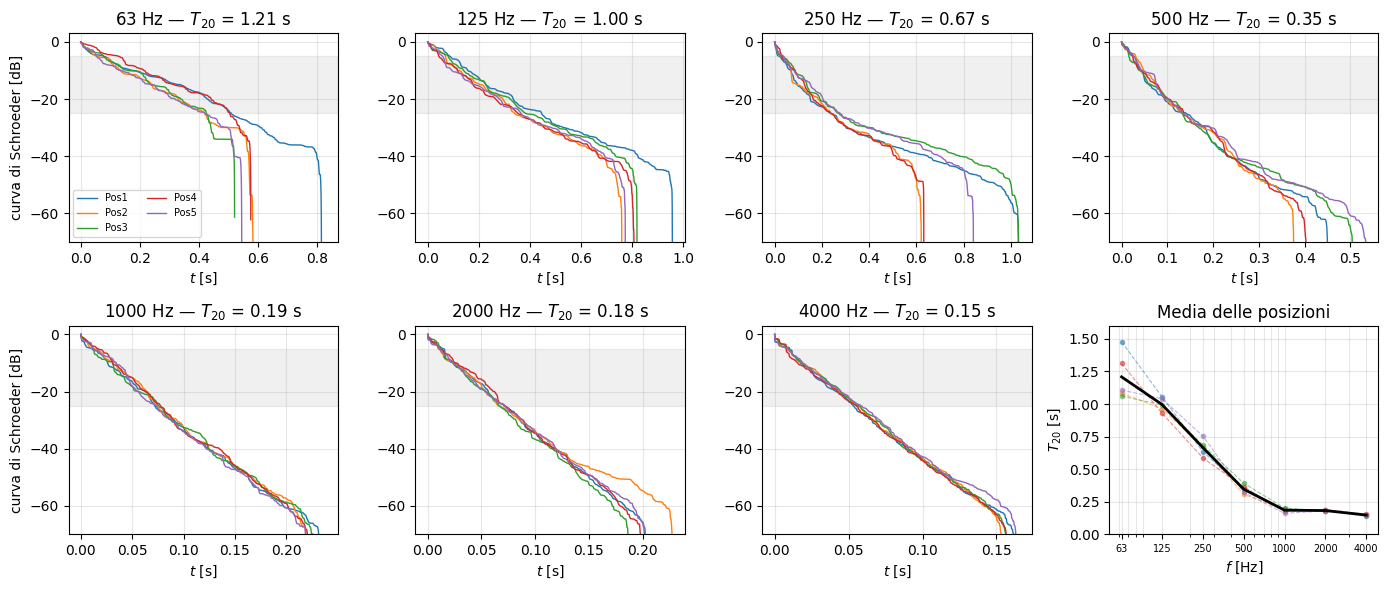

In [7]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(14, 6))

for k, fc in enumerate(BANDS):
    ax = axs.flat[k]
    for pos in POSITIONS:
        t, curva = curve[pos, fc]
        ax.plot(t, curva, lw=1, label=f'Pos{pos}')
    ax.axhspan(DB_BOT, DB_TOP, color='k', alpha=0.06)      # tratto di fit
    ax.set(title=f'{fc} Hz — $T_{{20}}$ = {T20[:, k].mean():.2f} s',
           ylim=(-70, 3), xlabel=f'$t$ [s]')
    ax.grid(alpha=0.3)
axs.flat[0].set_ylabel('curva di Schroeder [dB]')
axs.flat[4].set_ylabel('curva di Schroeder [dB]')
axs.flat[0].legend(fontsize=7, ncol=2)

# ultimo pannello: T20 in funzione della frequenza
ax = axs.flat[-1]
for i in range(len(POSITIONS)):
    ax.semilogx(BANDS, T20[i], 'o--', lw=0.8, ms=3, alpha=0.5)
ax.semilogx(BANDS, T20.mean(axis=0), 'k-', lw=2, label='media 5 pos.')
ax.set(title='Media delle posizioni', xlabel=f"$f$ [Hz]", ylabel='$T_{20}$ [s]', ylim=(0, 1.6))
ax.set_xticks(BANDS, [str(b) for b in BANDS], fontsize=7)
# ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

fig.tight_layout()
fig.savefig(FIG_DIR / 'curve_schroeder_per_banda.pdf')
plt.show()

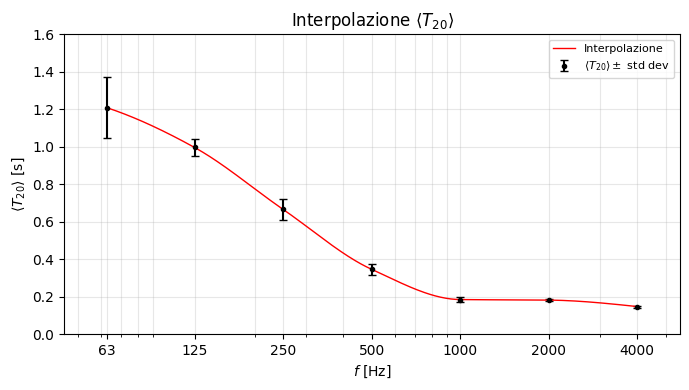

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

dati = np.loadtxt(RESULTS_DIR / 't20_bande_ottava.csv', delimiter=',', skiprows=1)
T20_media, T20_std = [], []
for fc in BANDS:
    valori = dati[dati[:, 1] == fc, 2]
    T20_media.append(valori.mean())
    T20_std.append(valori.std())    # radice della varianza: stessa unita' di misura di T20 [s]

interpolazione = PchipInterpolator(np.log10(BANDS), T20_media)
f_fine = np.logspace(np.log10(BANDS[0]), np.log10(BANDS[-1]), 300)
T20_interp = interpolazione(np.log10(f_fine))

np.savetxt(RESULTS_DIR / 't20_interpolato.csv', np.column_stack([f_fine, T20_interp]),
           delimiter=',', fmt='%.4f', header='f_hz,T20_s', comments='')

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(BANDS, T20_media, yerr=T20_std, fmt='o', color='black', ms=3, capsize=3, label='$\\langle T_{20} \\rangle \\pm$ std dev')
ax.semilogx(f_fine, T20_interp, '-', lw=1, color='red', label='Interpolazione')

ax.set(title='Interpolazione $\\langle T_{20} \\rangle$', xlabel='$f$ [Hz]', ylabel='$\\langle T_{20} \\rangle$ [s]',
       xlim=(45, 5600), ylim=(0, 1.6))
ax.set_xticks(BANDS, [str(b) for b in BANDS])
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

fig.tight_layout()
fig.savefig(FIG_DIR / 't20_interpolato.pdf')
plt.show()


## Analisi in frequenza
Trasformata di Fourier delle IR.

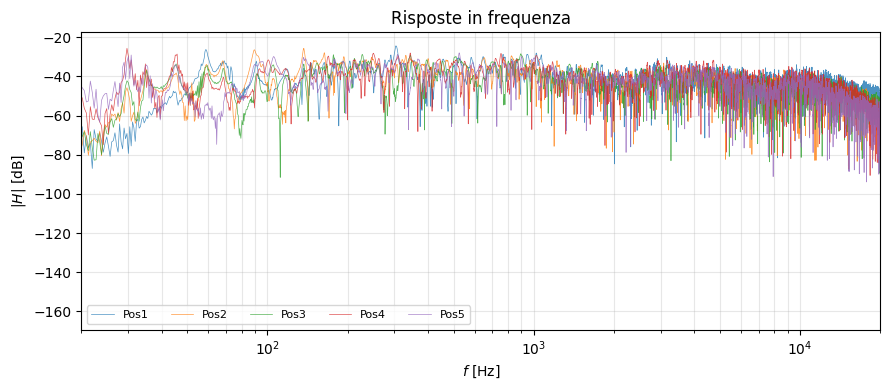

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from rew_io import ROOM_DIR, RESULTS_DIR, CAL_DIR, read_mdat, load_rew_export
from integration import BandDecay

POSITIONS = [1,2,3,4,5]
FRs = []
FREQs = []

# File di calibrazione della catena di misura
f_mic, db_mic = load_rew_export(CAL_DIR / 'ecm8000_mic.cal')
f_sc, db_sc = load_rew_export(CAL_DIR / 'soundcard_minifuse4.cal')

for i, pos in enumerate(POSITIONS):
    measure = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    ir = measure.mean_ir
    temp_fft = np.fft.rfft(ir)
    FRs.append(20 * np.log10(np.abs(temp_fft) + 1e-30))

    nfft = len(ir)
    fs = measure.fs
    FREQs.append(np.fft.rfftfreq(nfft, 1 / fs))

    # Le tabelle di calibrazione hanno frequenze diverse da quelle della FFT:
    # le interpoliamo sulle frequenze della FFT e sottraiamo la correzione in dB
    cal_db = np.interp(FREQs[i], f_mic, db_mic) + np.interp(FREQs[i], f_sc, db_sc)
    FRs[i] = FRs[i] - cal_db

# media in potenza delle 5 posizioni
potenze = []
for i in range(len(POSITIONS)):
    potenze.append(10 ** (FRs[i] / 10))
FR_media = 10 * np.log10(np.mean(potenze, axis=0))

banda = (FREQs[0] >= 20) & (FREQs[0] <= 1000)
colonne = [FREQs[0][banda]] + [FR[banda] for FR in FRs] + [FR_media[banda]]
np.savetxt(RESULTS_DIR / 'risposte_in_frequenza.csv', np.column_stack(colonne), delimiter=',', fmt='%.4f',
           header='f_hz,' + ','.join(f'Pos{pos}' for pos in POSITIONS) + ',media', comments='')

fig, ax = plt.subplots(figsize=(9, 4))
for i, pos in enumerate(POSITIONS):
    ax.semilogx(FREQs[i], FRs[i], lw=0.5, alpha=0.8, label=f'Pos{pos}')

ax.set(xlim=(20, 20000), xlabel=r'$f$ [Hz]', ylabel=r'$|H|$ [dB]',
       title='Risposte in frequenza')
ax.legend(loc='lower left', ncol=5, fontsize=8)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig(FIG_DIR / 'risposta_in_frequenza.pdf')
plt.show()

## Modi teorici della stanza
Per una stanza rettangolare le frequenze dei modi dipendono da triplette di interi $n_x, n_y, n_z$ non negativi.

$$f_{n_x n_y n_z} = \frac{c}{2}\sqrt{\left(\frac{n_x}{L_x}\right)^2 + \left(\frac{n_y}{L_y}\right)^2 + \left(\frac{n_z}{L_z}\right)^2}$$

Calcolo dei modi e confronto con risposta in frequenza media.

In [10]:
import numpy as np
import pandas as pd

LX, LY, LZ = 5.70, 4.80, 2.48            # m
V  = LX * LY * LZ                        # 67.85 m^3
S  = 2 * (LX*LY + LX*LZ + LY*LZ)         # 106.8 m^2
c  = 343.0                               # m/s (~20 ºC)

F_LIM = 400    # Hz, oltre la regione modale: i modi servono anche per l'overlap modale
N_LIM = int(2 * F_LIM * LX / c) + 1 # Indice massimo da provare, ottenuto invertendo n_X da f_lim

righe = []
for nx in range(N_LIM + 1):
    for ny in range(N_LIM + 1):
        for nz in range(N_LIM + 1):
            if nx == 0 and ny == 0 and nz == 0:
                continue
            f = c / 2 * np.sqrt((nx / LX)**2 + (ny / LY)**2 + (nz / LZ)**2)
            if f > F_LIM:
                continue
            # il tipo dipende da quanti indici sono diversi da zero
            indici_non_nulli = (nx > 0) + (ny > 0) + (nz > 0)
            if indici_non_nulli == 1:
                tipo = 'assiale'
            elif indici_non_nulli == 2:
                tipo = 'tangenziale'
            else:
                tipo = 'obliquo'
            righe.append((f, nx, ny, nz, tipo))

modi = pd.DataFrame(righe, columns=['f_hz', 'nx', 'ny', 'nz', 'tipo']).sort_values('f_hz')
modi.to_csv(RESULTS_DIR / 'modi_teorici.csv', index=False, float_format='%.3f')
print(f'Salvati {len(modi)} modi fino a {F_LIM} Hz in {RESULTS_DIR / "modi_teorici.csv"}')


Salvati 572 modi fino a 400 Hz in /Users/matteob/Code/acoustics/data/results/modi_teorici.csv


Modi non obliqui sotto 249 Hz: 85
  assiale      17
  tangenziale  68

Primi 15 modi:
  f [Hz]   (nx, ny, nz)   tipo
    30.1   (1, 0, 0)      assiale
    35.7   (0, 1, 0)      assiale
    46.7   (1, 1, 0)      tangenziale
    60.2   (2, 0, 0)      assiale
    69.2   (0, 0, 1)      assiale
    70.0   (2, 1, 0)      tangenziale
    71.5   (0, 2, 0)      assiale
    75.4   (1, 0, 1)      tangenziale
    77.5   (1, 2, 0)      tangenziale
    77.8   (0, 1, 1)      tangenziale
    90.3   (3, 0, 0)      assiale
    91.7   (2, 0, 1)      tangenziale
    93.4   (2, 2, 0)      tangenziale
    97.1   (3, 1, 0)      tangenziale
    99.4   (0, 2, 1)      tangenziale


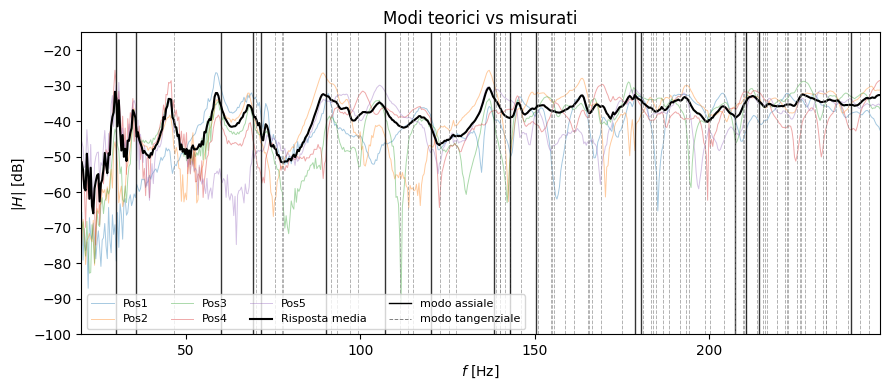

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

F_MAX = 249    # Hz, limite della regione modale mostrata

modi = pd.read_csv(RESULTS_DIR / 'modi_teorici.csv')
modi = modi[(modi.tipo != 'obliquo') & (modi.f_hz <= F_MAX)]

# riepilogo
print(f'Modi non obliqui sotto {F_MAX} Hz: {len(modi)}')
for tipo in ['assiale', 'tangenziale']:
    print(f'  {tipo:<12} {(modi.tipo == tipo).sum()}')

# tabella
N_TAB = 15 # quanti modi stampare
print(f'\nPrimi {N_TAB} modi:')
print(f'{"f [Hz]":>8}   {"(nx, ny, nz)":<14} tipo')
for f, nx, ny, nz, tipo in modi.head(N_TAB).itertuples(index=False):
    print(f'{f:>8.1f}   {str((nx, ny, nz)):<14} {tipo}')

fr = pd.read_csv(RESULTS_DIR / 'risposte_in_frequenza.csv')

# plot previsione vs misure
fig, ax = plt.subplots(figsize=(9, 4))
for pos in POSITIONS:
    ax.plot(fr.f_hz, fr[f'Pos{pos}'], lw=0.7, alpha=0.4, label=f'Pos{pos}')
ax.plot(fr.f_hz, fr.media, color='black', lw=1.5, label='Risposta media')

for f, nx, ny, nz, tipo in modi.itertuples(index=False):
    if tipo == 'assiale':
        ax.axvline(f, color='black', lw=1, alpha=0.8)
    else:
        ax.axvline(f, color='gray', lw=0.7, alpha=0.6, ls='--')

ax.plot([], [], color='black', lw=1, label='modo assiale')
ax.plot([], [], color='gray', lw=0.7, ls='--', label='modo tangenziale')

ax.set(xlim=(20, F_MAX), ylim=(-100, -15), xlabel=r'$f$ [Hz]', ylabel=r'$|H|$ [dB]',
       title='Modi teorici vs misurati')
ax.legend(loc='lower left', ncol=4, fontsize=8)
# ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
fig.savefig(FIG_DIR / 'modi_teorici_vs_misura.pdf')
plt.show()

## Confronto tra modi previsti e misurati
I picchi della risposta media in potenza sono rilevati con `find_peaks`. Ogni picco è abbinato al modo assiale o tangenziale più vicino, se cade entro la tolleranza; se più picchi cadono sullo stesso modo si tiene il più prominente. Lo scostamento $\Delta f = f_{mis} - f_{teo}$ misura quanto la previsione a pareti rigide si discosta dalla misura.

In [12]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

F_MIN, F_MAX = 25, 200    # Hz
PROMINENZA = 5            # dB
TOLLERANZA = 0.04         # scostamento relativo massimo per l'abbinamento

fr = pd.read_csv(RESULTS_DIR / 'risposte_in_frequenza.csv')
fr = fr[(fr.f_hz >= F_MIN) & (fr.f_hz <= F_MAX)]
indici, proprieta = find_peaks(fr.media.to_numpy(), prominence=PROMINENZA)
f_picchi = fr.f_hz.to_numpy()[indici]
prominenze = proprieta['prominences']

modi = pd.read_csv(RESULTS_DIR / 'modi_teorici.csv')
candidati = modi[modi.tipo != 'obliquo'].reset_index(drop=True)
t20 = np.loadtxt(RESULTS_DIR / 't20_interpolato.csv', delimiter=',', skiprows=1)

abbinamenti = {} # indice del modo -> (frequenza del picco, prominenza)
for f_mis, prom in zip(f_picchi, prominenze):
    distanze = np.abs(candidati.f_hz - f_mis)
    j = distanze.idxmin()
    if distanze[j] > TOLLERANZA * candidati.f_hz[j]:
        continue
    if j not in abbinamenti or prom > abbinamenti[j][1]:
        abbinamenti[j] = (f_mis, prom)

righe = []
for j, (f_mis, prom) in abbinamenti.items():
    f_teo, nx, ny, nz, tipo = candidati.loc[j]
    B = 2.2 / np.interp(f_teo, t20[:, 0], t20[:, 1])    # larghezza a meta' potenza; sotto 63 Hz vale T(63 Hz)
    righe.append((nx, ny, nz, tipo, f_teo, f_mis, f_mis - f_teo, B, (f_mis - f_teo) / f_teo * 100))

colonne = ['nx', 'ny', 'nz', 'tipo', 'f_teo_hz', 'f_mis_hz', 'delta_f_hz', 'B_hz', 'scostamento_pct']
confronto = pd.DataFrame(righe, columns=colonne).sort_values('f_teo_hz')
confronto.to_csv(RESULTS_DIR / 'confronto_modi.csv', index=False, float_format='%.2f')
print(confronto.to_string(index=False, float_format='%.2f'))

media = confronto.scostamento_pct.mean()
dev_std = confronto.scostamento_pct.std()
print(f'\nModi abbinati: {len(confronto)} su {len(f_picchi)} picchi '
      f'({(confronto.tipo == "assiale").sum()} assiali, {(confronto.tipo == "tangenziale").sum()} tangenziali)')
print(f'Scostamento relativo: {media:.2f} % (dev. std. {dev_std:.2f} %, errore della media {dev_std / np.sqrt(len(confronto)):.2f} %)')


 nx  ny  nz        tipo  f_teo_hz  f_mis_hz  delta_f_hz  B_hz  scostamento_pct
  1   0   0     assiale     30.09     29.66       -0.42  1.82            -1.41
  0   1   0     assiale     35.73     34.79       -0.94  1.82            -2.63
  1   1   0 tangenziale     46.71     45.04       -1.67  1.82            -3.57
  2   0   0     assiale     60.17     58.59       -1.58  1.82            -2.63
  0   0   1     assiale     69.15     68.12       -1.04  1.85            -1.50
  3   0   0     assiale     90.26     89.36       -0.91  1.98            -1.01
  0   3   0     assiale    107.19    105.47       -1.72  2.09            -1.60
  0   0   2     assiale    138.31    136.96       -1.34  2.30            -0.97
  3   0   2 tangenziale    165.16    163.70       -1.46  2.52            -0.88
  0   5   0     assiale    178.65    178.71        0.06  2.64             0.04

Modi abbinati: 10 su 12 picchi (8 assiali, 2 tangenziali)
Scostamento relativo: -1.62 % (dev. std. 1.05 %, errore della media 0.33

## Calcolo frequenza di soglia
Si deriva una frequenza di soglia imponendo l'overlap modale uguale a 3, come richiesto dal criterio di Schroeder. La formula continua dell'overlap modale si ottiene combinando il conteggio teorico della densità modale che va con $f^2$ e la larghezza di banda, estrapolata dalla curva interpolata dai dati del tempo di riverberazione.

*Un ulteriore confronto si può eventualmente fare con il conteggio effettivo dei modi della stanza, che restituisce un valore leggermente diverso.*

M = 3 dai modi teorici:          194.7 Hz
M = 3 dalla formula continua:    193.2 Hz


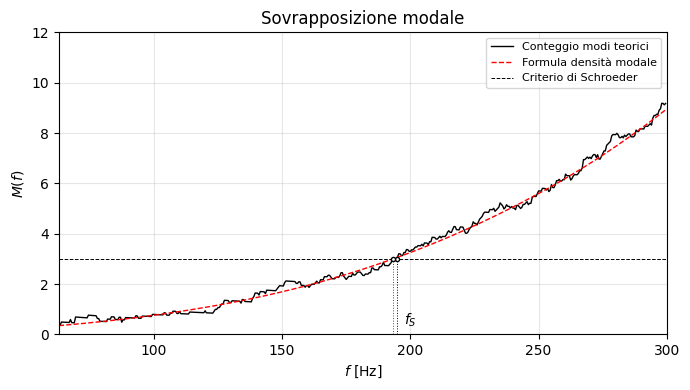

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

frequenze_modi = pd.read_csv(RESULTS_DIR / 'modi_teorici.csv')['f_hz'].to_numpy()
t20_interp = np.loadtxt(RESULTS_DIR / 't20_interpolato.csv', delimiter=',', skiprows=1)
f_t20, T_t20 = t20_interp[:, 0], t20_interp[:, 1]

f_asse = np.arange(63, 300, 0.5) # sotto 63 Hz mancano dati T20
M = []
for f in f_asse:
    f_min = f * 2 ** (-1 / 6)
    f_max = f * 2 ** (1 / 6)
    n_modi = np.sum((frequenze_modi >= f_min) & (frequenze_modi < f_max))
    densita = n_modi / (f_max - f_min)

    T = np.interp(f, f_t20, T_t20)
    larghezza_modo = 2.2 / T        # banda a -3 dB di un modo [Hz]
    M.append(densita * larghezza_modo)
M = np.array(M)

# confronto con formula continua
densita_formula = 4 * np.pi * V * f_asse**2 / c**3 + np.pi * S * f_asse / (2 * c**2) + LT / (8 * c)
M_formula = densita_formula * 2.2 / np.interp(f_asse, f_t20, T_t20)

def intercetta(f, M, soglia=3):
    # interpolazione lineare tra i due punti della griglia a cavallo della soglia
    i = np.argmax(M >= soglia)
    return np.interp(soglia, M[i - 1:i + 1], f[i - 1:i + 1])

f_soglia = intercetta(f_asse, M)
f_soglia_formula = intercetta(f_asse, M_formula)
f_schroeder = 2000 * np.sqrt(np.interp(f_soglia, f_t20, T_t20) / V)

print(f'M = 3 dai modi teorici:          {f_soglia:.1f} Hz')
print(f'M = 3 dalla formula continua:    {f_soglia_formula:.1f} Hz')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(f_asse, M, color='black', lw=1, label='Conteggio modi teorici')
ax.plot(f_asse, M_formula, color='red', lw=1, ls='--', label='Formula densità modale')
ax.axhline(3, color='black', ls='--', lw=0.7, alpha=1, label='Criterio di Schroeder')

# proiezione delle intercette con M = 3 sull'asse delle frequenze
ax.vlines([f_soglia, f_soglia_formula], 0, 3, colors=['black', 'red'], lw=0.7, ls=':')
ax.plot([f_soglia, f_soglia_formula], [3, 3], 'o', ms=3, color='black', mfc='white')
ax.text(f_soglia + 3, 0.2, '$f_S$', ha='left', va='bottom')

ax.set(xlabel=r'$f$ [Hz]', ylabel='$M(f)$', title='Sovrapposizione modale', xlim=(63, 300), ylim=(0, 12))
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / 'overlap_modale.pdf')
plt.show()

## Regime statistico
Sopra la frequenza di soglia la risposta in un punto è la somma di molti modi sovrapposti con ampiezze e fasi casuali, quindi $H(f)$ si comporta come un processo gaussiano, la cui correlazione in frequenza dipende solo dallo smorzamento. Schroeder ne ricava che la spaziatura media fra massimi adiacenti di $|H(f)|$ è indipendente dalla densità modale.

$$\langle \Delta f_{max} \rangle \simeq \frac{\delta}{\sqrt{3}} = \frac{6.91}{\sqrt{3}\,T} \simeq \frac{4}{T}$$

Il rapporto $r = \langle \Delta f_{max} \rangle / (4/T)$ deve quindi tendere a 1 nel regime statistico.
Per ogni banda d'ottava e ogni posizione la IR è troncata all'estremo di Lundeby già usato per il $T_{20}$.
Si contano tutti i massimi della risposta $H$ misurata con il metodo `find_peaks`.

 fc_hz  T20_s  spaziatura_th_hz  spaziatura_media_hz  rapporto  std_dev
    63   1.21              3.31                 4.84      1.46     0.45
   125   1.00              4.01                 5.41      1.35     0.08
   250   0.67              6.00                 5.86      0.98     0.09
   500   0.35             11.52                13.06      1.13     0.15
  1000   0.19             21.51                21.00      0.98     0.06
  2000   0.18             21.84                21.94      1.00     0.05
  4000   0.15             26.90                26.70      0.99     0.02


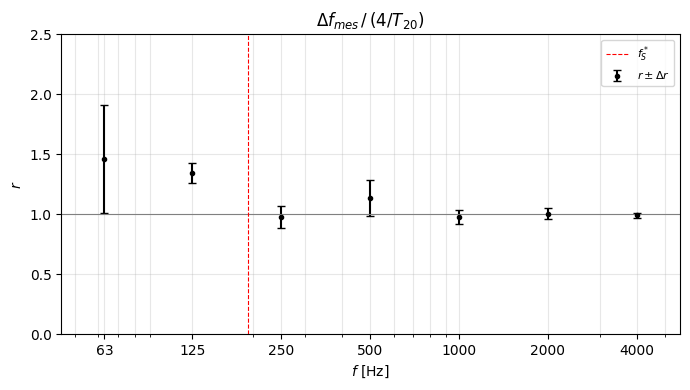

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

from rew_io import ROOM_DIR, read_mdat

t20 = pd.read_csv(RESULTS_DIR / 't20_bande_ottava.csv')

irs = []
for pos in POSITIONS:
    m = read_mdat(ROOM_DIR / f'Danger_Pos{pos}.mdat')
    irs.append(m.mean_ir)
fs = m.fs
f = np.fft.rfftfreq(len(irs[0]), 1 / fs)

righe = []
for fc in BANDS:
    T = t20[t20.fc_hz == fc].T20_s.mean()
    f_min, f_max = fc / np.sqrt(2), fc * np.sqrt(2)
    banda = (f >= f_min) & (f < f_max)

    rapporti = []
    for i, pos in enumerate(POSITIONS):
        t_cross = t20[(t20.posizione == pos) & (t20.fc_hz == fc)].t_cross_s.iloc[0]

        # finestra da 5 ms prima del picco all'estremo di Lundeby, con discesa a mezza Hann nell'ultimo 10%
        picco = np.argmax(np.abs(irs[i]))
        inizio = picco - int(0.005 * fs)
        fine = min(picco + int(t_cross * fs), len(irs[i]))
        n_discesa = (fine - inizio) // 10
        finestra = np.zeros(len(irs[i]))
        finestra[inizio:fine] = 1
        finestra[fine - n_discesa:fine] = np.hanning(2 * n_discesa)[n_discesa:]

        H = 20 * np.log10(np.abs(np.fft.rfft(irs[i] * finestra)) + 1e-30)
        n_massimi = len(find_peaks(H[banda])[0])
        rapporti.append((f_max - f_min) / n_massimi / (4 / T))

    righe.append((fc, T, 4 / T, np.mean(rapporti) * 4 / T, np.mean(rapporti), np.std(rapporti)))

colonne = ['fc_hz', 'T20_s', r'spaziatura_th_hz', 'spaziatura_media_hz', 'rapporto', 'std_dev']
regime = pd.DataFrame(righe, columns=colonne)
regime.to_csv(RESULTS_DIR / 'regime_statistico.csv', index=False, float_format='%.3f')
print(regime.to_string(index=False, float_format='%.2f'))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(regime.fc_hz, regime.rapporto, yerr=regime.std_dev, fmt='o', color='black', ms=3, capsize=3,
            label=r'$r \pm \Delta r$')
ax.axhline(1, color='gray', lw=0.8)
ax.axvline(f_soglia_formula, color='red', lw=0.8, ls='--', label=f'$f_S^*$')

ax.set(xscale='log', xlabel=r'$f$ [Hz]', ylabel='$r$', title='$\\Delta f_{mes} \\,/ \\, (4/T_{20})$',
       xlim=(45, 5600), ylim=(0, 2.5))
ax.set_xticks(BANDS, [str(b) for b in BANDS])
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
fig.savefig(FIG_DIR / 'regime_statistico.pdf')
plt.show()
